In [1]:
import numpy as np

In [2]:
def relu(z):
    return np.maximum(0,z)
def relu_derivative(z):
    return (z>0).astype(float)
def sigmoid(z):
    return 1/(1+np.exp(-z))


In [3]:
X = np.array([
    [0,0],
    [0,1],
    [1,0],
    [1,1]
])
Y = np.array([
    [0],
    [1],
    [1],
    [1]
])

In [4]:
np.random.seed(42)
W1 = np.random.randn(2,2)*0.5
b1 = np.zeros((1,2))

W2 = np.random.randn(2,1)*0.5
b2 = np.zeros((1,1))

In [5]:
def BCE(y_true, y_pred):
    epsilon = 1e-15
    y_pred = np.clip(
        y_pred, epsilon, 1-epsilon
    )

    loss = -(y_true * np.log(y_pred) + (1-y_true) * np.log(1-y_pred))
    return np.mean(loss)

In [6]:
def forward_propagation(X, W1, b1, W2, b2):
    Z1 = np.dot(X, W1)+b1
    A1 = relu(Z1)
    Z2 = np.dot(A1, W2)+b2
    A2 = sigmoid(Z2)

    return Z1, A1, Z2, A2

In [9]:
def backpropagation(X, Y, Z1, A1, A2, W2 ):
    m = X.shape[0]
    # Output layer
    dZ2 = A2-Y
    dW2 = np.dot(A1.T, dZ2)/m
    db2 = np.sum(dZ2, axis = 0, keepdims= True)/m

    #Hidden layer
    dA1 = np.dot(dZ2, W2.T)
    dZ1 = dA1 * relu_derivative(Z1)
    dW1 = np.dot(X.T, dZ1)/m
    db1 = np.sum(dZ1, axis = 0, keepdims = True)/m

    return dW1, db1, dW2, db2

In [10]:
learning_rate = 0.01
epochs = 10000

loss_history =[]

for epoch in range(epochs):
    Z1, A1, Z2, A2 = forward_propagation(X, W1, b1, W2, b2)

    #Calculate loss
    loss = BCE(Y, A2)
    loss_history.append(loss)

    #Back Propagation
    dW1, db1, dW2, db2 = backpropagation(X, Y, Z1, A1, A2, W2)

    #update parameters:
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    
    if epoch % 1000 == 0:
        print(f"Epoch: {epoch}, Loss: {loss:.6f}")

Epoch: 0, Loss: 0.732386
Epoch: 1000, Loss: 0.337512
Epoch: 2000, Loss: 0.177497
Epoch: 3000, Loss: 0.103369
Epoch: 4000, Loss: 0.068050
Epoch: 5000, Loss: 0.049144
Epoch: 6000, Loss: 0.037833
Epoch: 7000, Loss: 0.030470
Epoch: 8000, Loss: 0.025359
Epoch: 9000, Loss: 0.021634


In [11]:
Z1, A1, Z2, prediction = forward_propagation(X, W1, b1, W2, b2)

print("Predicted probabilities:")
print(prediction)

print("\n predicted classes:")
print((prediction>= 0.5). astype(int))


Predicted probabilities:
[[0.06304736]
 [0.99520627]
 [0.99468691]
 [0.99999827]]

 predicted classes:
[[0]
 [1]
 [1]
 [1]]


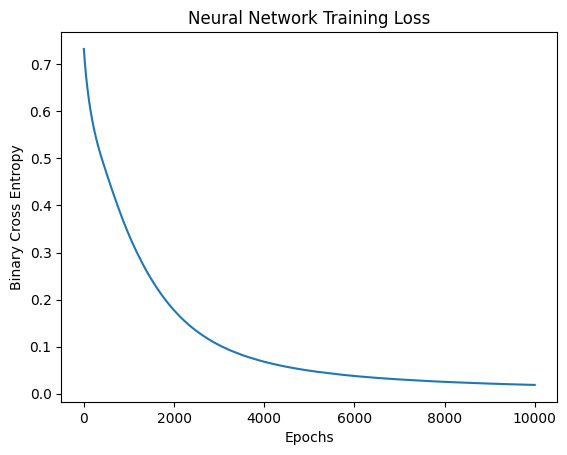

In [12]:
import matplotlib.pyplot as plt 
plt.plot(loss_history)
plt.xlabel("Epochs")
plt.ylabel("Binary Cross Entropy")
plt.title("Neural Network Training Loss")
plt.show()